### ASTR 8070: Astrostatistics
***N. Pol***
___

# Homework 4
### Due: Wednesday, Oct. 14 11.59pm CST
---

## Problem 1

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw4_data_1.npy`. This is a (10 x 2) numpy array, with voltage measurements in the first column and heteroscedastic voltage uncertainties in the second column. Compute the sample mean and the standard error on the sample mean for this data.

2) Fit the appropriate ln-likelihood function and find the best-fit mean voltage.

3) Compute and plot the Bayesian posterior probability density (*not the log posterior*) for the mean voltage assuming a uniform prior for the mean in the range 3 to 7. Make sure this posterior pdf is normalized!

4) By either drawing samples from this posterior, or using your gridded posterior pdf to make a cdf, find the equal-tailed 68.3% credible region for the mean, and compare the upper and lower boundaries to the sample mean plus/minus the standard error, respectively. *Also* find the MAP value of the mean.

5) Repeat (3) and (4) this time with a prior on the mean that is uniform in the range 4.6 to 5.4. 

6) Now, imagine that we read an old paper about the experiment that gave us the voltage measurements, and they found that the mean was actually $6\pm0.3$. Repeat (3) and (4) this time with a Gaussian prior on the mean centered at $6$ with standard deviation of $0.3$.

7) Plot all of the normalized posterior pdfs for $\mu$ from (3), (5), and (6) on the same plot, making sure that the xlim of the plot spans 0 to 10.

8) You have made sure that the posterior pdfs are properly normalized, but until now you have ignored the meaning of that normalization constant. It is the Bayesian evidence for the particular model you have applied! Compute the evidence under a new model where the prior for the mean is a delta function at the best-fit value you found in (1) *(think about this and don't just immediately go looking for a `scipy.stats` delta function)*. Compare this to the evidence found under the prior in (3). Taking ratios to make a Bayes factor, which model is favored? Is there much of an Occam penalty by having the wide prior compared to knowing the mean exactly? 

### Solution

Sample mean: 5.106
Standard error: 0.32838053806183115
Best-fit mean voltage: 4.942118214425304
Maximum log-likelihood: -16.048012714571367
Weighted mean: 4.942118214425304
Difference: 0.0
Posterior integral: 1.0000000000000002


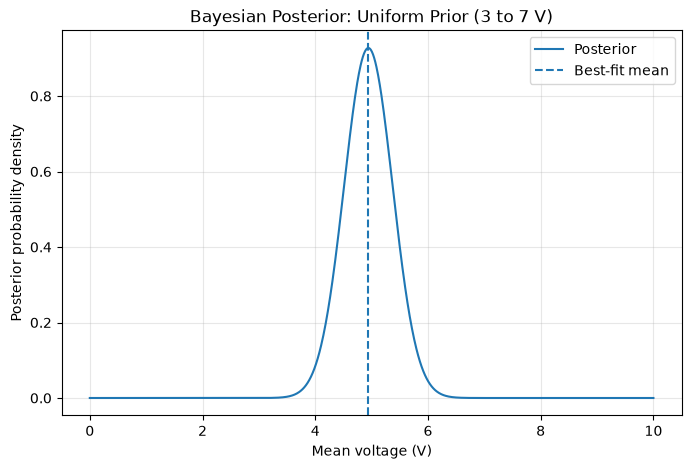

MAP estimate: 4.944944944944945
68.3% credible interval: 4.511559482267982 5.3726796664721865
Sample mean - SEM: 4.777619461938169
Sample mean + SEM: 5.434380538061831
Lower boundary difference: -0.266059979670187
Upper boundary difference: -0.0617008715896441
MAP estimate: 4.944944944944945
68.3% credible interval: 4.734842556997577 5.238591100156427
Posterior integral: 1.0


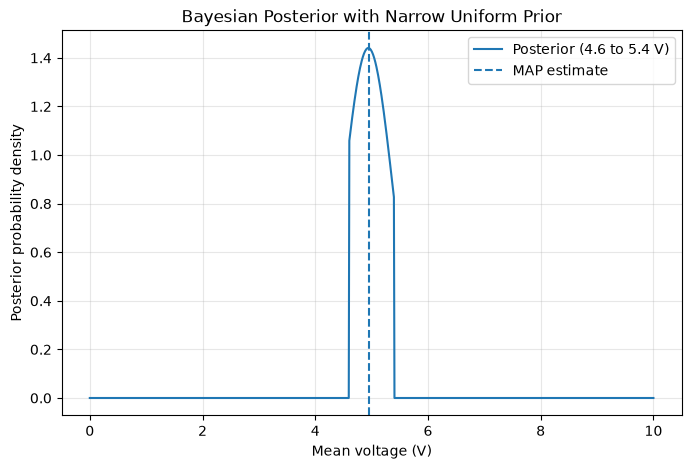

MAP estimate: 5.655655655655655
68.3% credible interval: 5.40761119998316 5.900247342643005
Posterior integral: 1.0000000000000002


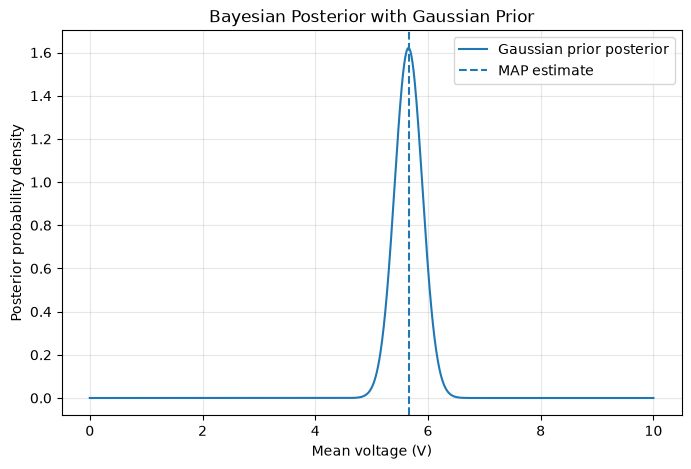

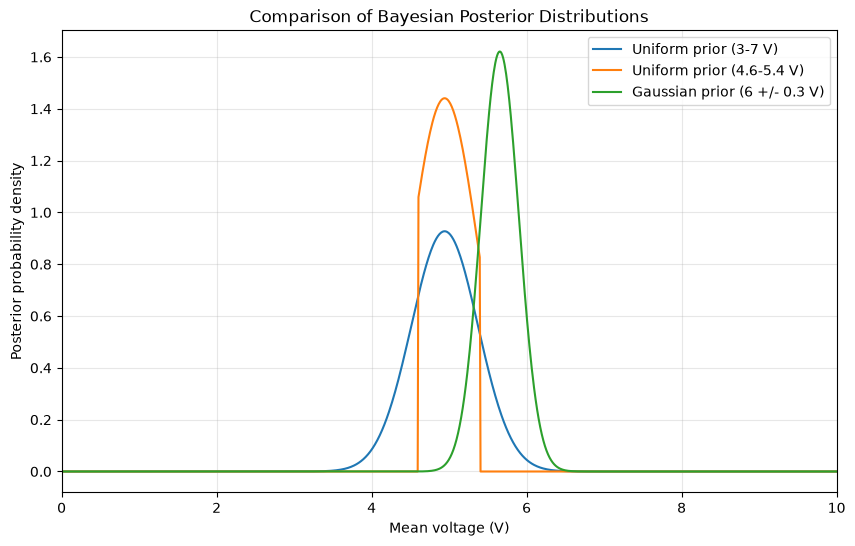

Delta-function evidence: 9.975417031611396e-08
Uniform-prior evidence: 2.8918716982047357e-08
Bayes factor (delta / uniform): 3.4494673597739833
The delta-function model is favored.


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize_scalar

# Load the voltage data
data = np.load(r"C:\Users\jolee\Documents\astrostats_ttu_fall26\coursework\homeworks\hw_data\hw4_data_1.npy")

# Separate voltages and their uncertainties
voltage = data[:, 0]
sigma = data[:, 1]

# Number of measurements
N = len(voltage)

# Calculate sample mean
sample_mean = np.mean(voltage)

# Calculate sample standard deviation
sample_std = np.std(voltage, ddof=1)

# Calculate standard error
sem = sample_std / np.sqrt(N)

print("Sample mean:", sample_mean)
print("Standard error:", sem)

# Define the Gaussian log-likelihood function
def log_likelihood(mu):
    return -0.5 * np.sum(
        np.log(2 * np.pi * sigma**2)
        + (voltage - mu)**2 / sigma**2
    )

# Find the mean that maximizes the log-likelihood
result = minimize_scalar(
    lambda mu: -log_likelihood(mu),
    bounds=(0, 10),
    method="bounded"
)

best_fit_mu = result.x

print("Best-fit mean voltage:", best_fit_mu)
print("Maximum log-likelihood:", log_likelihood(best_fit_mu))

weighted_mean = np.sum(voltage / sigma**2) / np.sum(1 / sigma**2)

print("Weighted mean:", weighted_mean)
print("Difference:", abs(best_fit_mu - weighted_mean))



# Create a grid of possible mean voltages
mu_grid = np.linspace(0, 10, 1000)

# Define the uniform prior
prior = np.where(
    (mu_grid >= 3) & (mu_grid <= 7),
    1 / 4,
    0
)

# Calculate likelihood on the grid
likelihood = np.exp(
    [log_likelihood(mu) for mu in mu_grid]
)

# Calculate the unnormalized posterior
posterior_unnorm = likelihood * prior

# Calculate the normalization constant (evidence)
evidence = np.trapezoid(posterior_unnorm, mu_grid)

# Normalize the posterior
posterior = posterior_unnorm / evidence

# Verify normalization
print("Posterior integral:", np.trapezoid(posterior, mu_grid))

# Plot the posterior
plt.figure(figsize=(8, 5))
plt.plot(mu_grid, posterior, label="Posterior")
plt.axvline(best_fit_mu, linestyle="--",
            label="Best-fit mean")

plt.xlabel("Mean voltage (V)")
plt.ylabel("Posterior probability density")
plt.title("Bayesian Posterior: Uniform Prior (3 to 7 V)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



# Find the MAP estimate
map_index = np.argmax(posterior)
map_mu = mu_grid[map_index]

# Calculate the cumulative distribution function (CDF)
cdf = np.zeros_like(posterior)

cdf[1:] = np.cumsum(
    (posterior[1:] + posterior[:-1]) / 2
    * np.diff(mu_grid)
)

# Find the equal-tailed 68.3% credible interval
lower = np.interp(0.1585, cdf, mu_grid)
upper = np.interp(0.8415, cdf, mu_grid)

# Compare with the sample mean +/- standard error
sem_lower = sample_mean - sem
sem_upper = sample_mean + sem

print("MAP estimate:", map_mu)
print("68.3% credible interval:", lower, upper)

print("Sample mean - SEM:", sem_lower)
print("Sample mean + SEM:", sem_upper)

print("Lower boundary difference:", lower - sem_lower)
print("Upper boundary difference:", upper - sem_upper)



# Define the narrower uniform prior
prior_narrow = np.where(
    (mu_grid >= 4.6) & (mu_grid <= 5.4),
    1 / 0.8,
    0
)

# Calculate the unnormalized posterior
posterior_narrow_unnorm = likelihood * prior_narrow

# Normalize the posterior
evidence_narrow = np.trapezoid(
    posterior_narrow_unnorm, mu_grid
)

posterior_narrow = posterior_narrow_unnorm / evidence_narrow

# Find the MAP estimate
map_narrow = mu_grid[np.argmax(posterior_narrow)]

# Calculate the CDF
cdf_narrow = np.zeros_like(posterior_narrow)

cdf_narrow[1:] = np.cumsum(
    (posterior_narrow[1:] + posterior_narrow[:-1]) / 2
    * np.diff(mu_grid)
)

# Find the 68.3% equal-tailed credible interval
lower_narrow = np.interp(0.1585, cdf_narrow, mu_grid)
upper_narrow = np.interp(0.8415, cdf_narrow, mu_grid)

print("MAP estimate:", map_narrow)
print("68.3% credible interval:", lower_narrow, upper_narrow)
print("Posterior integral:",
      np.trapezoid(posterior_narrow, mu_grid))

# Plot the new posterior
plt.figure(figsize=(8, 5))
plt.plot(mu_grid, posterior_narrow,
         label="Posterior (4.6 to 5.4 V)")

plt.axvline(map_narrow, linestyle="--",
            label="MAP estimate")

plt.xlabel("Mean voltage (V)")
plt.ylabel("Posterior probability density")
plt.title("Bayesian Posterior with Narrow Uniform Prior")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



# Define Gaussian prior centered at 6 V
prior_gaussian = stats.norm.pdf(mu_grid, loc=6, scale=0.3)

# Calculate unnormalized posterior
posterior_gaussian_unnorm = likelihood * prior_gaussian

# Normalize posterior
evidence_gaussian = np.trapezoid(
    posterior_gaussian_unnorm, mu_grid
)

posterior_gaussian = posterior_gaussian_unnorm / evidence_gaussian

# Find MAP estimate
map_gaussian = mu_grid[np.argmax(posterior_gaussian)]

# Calculate cumulative distribution function
cdf_gaussian = np.zeros_like(posterior_gaussian)

cdf_gaussian[1:] = np.cumsum(
    (posterior_gaussian[1:] + posterior_gaussian[:-1]) / 2
    * np.diff(mu_grid)
)

# Find 68.3% equal-tailed credible interval
lower_gaussian = np.interp(0.1585, cdf_gaussian, mu_grid)
upper_gaussian = np.interp(0.8415, cdf_gaussian, mu_grid)

print("MAP estimate:", map_gaussian)
print("68.3% credible interval:", lower_gaussian, upper_gaussian)
print("Posterior integral:",
      np.trapezoid(posterior_gaussian, mu_grid))

# Plot Gaussian-prior posterior
plt.figure(figsize=(8, 5))

plt.plot(mu_grid, posterior_gaussian,
         label="Gaussian prior posterior")

plt.axvline(map_gaussian, linestyle="--",
            label="MAP estimate")

plt.xlabel("Mean voltage (V)")
plt.ylabel("Posterior probability density")
plt.title("Bayesian Posterior with Gaussian Prior")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



# Plot all three normalized posterior distributions
plt.figure(figsize=(10, 6))

# Wide uniform prior (3 to 7 V)
plt.plot(mu_grid, posterior,
         label="Uniform prior (3-7 V)")

# Narrow uniform prior (4.6 to 5.4 V)
plt.plot(mu_grid, posterior_narrow,
         label="Uniform prior (4.6-5.4 V)")

# Gaussian prior (6 +/- 0.3 V)
plt.plot(mu_grid, posterior_gaussian,
         label="Gaussian prior (6 +/- 0.3 V)")

# Set axis limits
plt.xlim(0, 10)

# Label the graph
plt.xlabel("Mean voltage (V)")
plt.ylabel("Posterior probability density")
plt.title("Comparison of Bayesian Posterior Distributions")

plt.legend()
plt.grid(alpha=0.3)

plt.show()



# Evidence for the delta-function prior centered at the sample mean from Part 1
evidence_delta = np.exp(log_likelihood(sample_mean))

# Evidence for the wide uniform prior from Part 3
evidence_uniform = evidence

# Calculate the Bayes factor
bayes_factor = evidence_delta / evidence_uniform

print("Delta-function evidence:", evidence_delta)
print("Uniform-prior evidence:", evidence_uniform)
print("Bayes factor (delta / uniform):", bayes_factor)

# Determine which model is favored
if bayes_factor > 1:
    print("The delta-function model is favored.")
else:
    print("The wide uniform-prior model is favored.")

## Problem 2

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw4_data_2.npy`, which is a (3 x 20) numpy array that you used in `Lecture_9`. Set `x, y, sigma_y = data`. 

We're going to do some polynomial fits to this data just like in `Lecture 9`. However, in all cases you should **keep the $y$-intercept fixed at $-0.23$**. 

2) Use the following code to compute the un-normalized posterior pdf (i.e. just the likelihood x prior) on a grid of the linear coefficient (i.e. the slope) of a linear model, with a uniform prior between 0.5 and 1.5. Plot this posterior pdf. Remember this is just a one-dimensional model because the $y$-intercept is fixed. I advise a grid size of 100.

In [19]:
#Functions to do a polynomial fit, and compute the likelihood
def polynomial_fit(theta, x):
    """Polynomial model of degree (len(theta) - 1)"""
    # For a polynomial with order 1, this gives theta_0 + theta_1*x
    # For a polynomial with order 2, this gives theta_0 + theta_1*x + theta_2*x^2, etc.
    return sum(t * x ** n for (n, t) in enumerate(theta))

# compute the data log-likelihood given a model
def logL(theta, data, model=polynomial_fit):
    """Gaussian log-likelihood of the model at theta"""
    x, y, sigma_y = data
    y_fit = model(theta, x)
    return sum(scipy.stats.norm.logpdf(*args) 
               for args in zip(y, y_fit, sigma_y))

3) Using your 1D gridded likelihood-x-prior, compute the Bayesian evidence of this linear model. This may be a big number!

4) Now compute the joint 2D posterior pdf (again just the likelihood x prior) of linear and quadratic coefficients of a quadratic model. Give the linear coefficient a uniform prior between 0.5 and 1.5. Give the quadratic coefficient a uniform prior between -1 and 0.25. Plot this two-dimensional posterior. Remember this is a two-dimensional model because the $y$-intercept is fixed. I advise a grid size of 100 in each model dimension.

5) Using your 2D gridded likelihood-x-prior, compute the Bayesian evidence of the quadratic model. 

6) Calculate the Bayes factor for a linear versus quadratic model. How does this compare/contrast with the BIC model comparison in the lecture? 

### Solution

Data shape: (3, 20)
Number of measurements: 20
x: [0.42 0.72 0.   0.3  0.15 0.09 0.19 0.35 0.4  0.54 0.42 0.69 0.2  0.88
 0.03 0.67 0.42 0.56 0.14 0.2 ]
y: [ 0.33  0.41 -0.25  0.01 -0.05 -0.05 -0.12  0.26  0.29  0.39  0.31  0.42
 -0.01  0.58 -0.2   0.52  0.15  0.32 -0.13 -0.09]
sigma_y: [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1]


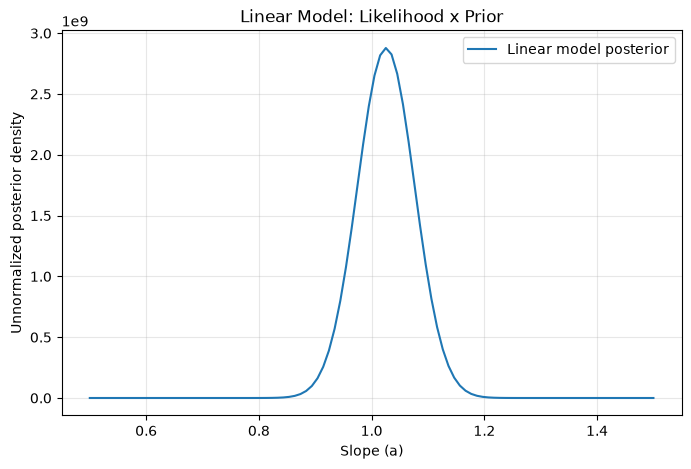

Linear model evidence: 365684733.16065943
Best-fit slope: 1.0252525252525253


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import stats

# Load the data for Problem 2
data = np.load(
    r"C:\Users\jolee\Documents\astrostats_ttu_fall26\coursework\homeworks\hw_data\hw4_data_2.npy"
)

# Separate the three rows
x, y, sigma_y = data

# Check the shape of the data
print("Data shape:", data.shape)
print("Number of measurements:", len(x))

# Display the data
print("x:", x)
print("y:", y)
print("sigma_y:", sigma_y)


# Create a grid of 100 possible slopes
a_grid = np.linspace(0.5, 1.5, 100)

# Define the uniform prior
prior_linear = np.ones_like(a_grid)

# Calculate the log-likelihood for each slope
log_likelihood_linear = np.array([
    logL([-0.23, a], data) for a in a_grid
])

# Convert log-likelihood to likelihood
likelihood_linear = np.exp(log_likelihood_linear)

# Calculate the unnormalized posterior
posterior_linear = likelihood_linear * prior_linear

# Plot the posterior
plt.figure(figsize=(8, 5))

plt.plot(a_grid, posterior_linear,
         label="Linear model posterior")

plt.xlabel("Slope (a)")
plt.ylabel("Unnormalized posterior density")
plt.title("Linear Model: Likelihood x Prior")

plt.legend()
plt.grid(alpha=0.3)
plt.show()





# Calculate Bayesian evidence for the linear model
evidence_linear = np.trapezoid(posterior_linear, a_grid)

# Find the slope with the highest posterior density
best_slope = a_grid[np.argmax(posterior_linear)]

print("Linear model evidence:", evidence_linear)
print("Best-fit slope:", best_slope)






# Create grids for the linear and quadratic coefficients
a_grid_2d = np.linspace(0.5, 1.5, 100)
b_grid_2d = np.linspace(-1, 0.25, 100)

# Create a 2D grid
A, B = np.meshgrid(a_grid_2d, b_grid_2d)

# Define the normalized joint uniform prior
prior_quadratic = 1 / ((1.5 - 0.5) * (0.25 - (-1)))

# Create an array to store the posterior values
posterior_quadratic = np.zeros_like(A)

# Calculate likelihood x prior for every combination
for i in range(100):
    for j in range(100):

        a = A[i, j]
        b = B[i, j]

        # Fixed intercept, linear coefficient, quadratic coefficient
        theta = [-0.23, a, b]

        # Calculate the likelihood
        likelihood_value = np.exp(logL(theta, data))

        # Calculate unnormalized posterior
        posterior_quadratic[i, j] = likelihood_value * prior_quadratic

# Plot the 2D posterior
plt.figure(figsize=(9, 6))

plt.contourf(A, B, posterior_quadratic, levels=30)
plt.colorbar(label="Unnormalized posterior density")

plt.xlabel("Linear coefficient (a)")
plt.ylabel("Quadratic coefficient (b)")
plt.title("Joint Posterior for Quadratic Model")

plt.show()







# Integrate over a
integral_a = np.trapezoid(
    posterior_quadratic,
    a_grid_2d,
    axis=1
)

# Integrate over b
evidence_quadratic = np.trapezoid(
    integral_a,
    b_grid_2d
)

# Find the best-fit parameters
best_index = np.unravel_index(
    np.argmax(posterior_quadratic),
    posterior_quadratic.shape
)

best_a = A[best_index]
best_b = B[best_index]

print("Quadratic model evidence:", evidence_quadratic)
print("Best-fit a:", best_a)
print("Best-fit b:", best_b)







# Calculate Bayes factor
bayes_factor_2 = evidence_quadratic / evidence_linear

print("Linear evidence:", evidence_linear)
print("Quadratic evidence:", evidence_quadratic)
print("Bayes factor (quadratic / linear):", bayes_factor_2)

# Interpret the result
if bayes_factor_2 > 1:
    print("The quadratic model is favored.")
elif bayes_factor_2 < 1:
    print("The linear model is favored.")
else:
    print("Both models have equal evidence.")